## Wie viele Aktien bruacht ein Portfolio? 

Am wie vielen Aktien lohnt sich Streeung kaum noch? 
Untersuchung mit Hilfe von Monte Carlo Simulationen

In [177]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import PercentFormatter
import yfinance as yf

START = "2016-01-01"
END = "2026-09-30"
SEED = 42
N_SIMS = 1000
SIZES = range(1,31)

COLORS = ["#12302b", "#b39256", "#9fb1aa", "#5e6b67"]   # dark green, gold, sage, grey (website)

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,          # no frame at the top ...
    "axes.spines.right": False,        # ... and on the right
    "axes.edgecolor": COLORS[3],       # remaining axes in grey instead of black
    "axes.labelcolor": COLORS[3],
    "xtick.color": COLORS[3],
    "ytick.color": COLORS[3],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",      # title left-aligned, like a heading
    "axes.titlecolor": COLORS[0],
    "grid.color": "#e4e8e6",           # very light grid lines
    "grid.linewidth": 0.8,
})


In [178]:
TICKERS = {                        # ticker -> sector
    "ADS.DE": "Consumer", 
    "AIR.DE": "Industrials", 
    "ALV.DE": "Financials", 
    "BAS.DE": "Chemicals", 
    "BAYN.DE": "Healthcare", 
    "BEI.DE": "Consumer", 
    "BMW.DE": "Autos", 
    "BNR.DE": "Chemicals",
    "CBK.DE": "Financials", 
    "CON.DE": "Autos", 
    "DB1.DE": "Financials", 
    "DBK.DE": "Financials",
    "DHL.DE": "Industrials", 
    "DTE.DE": "Tech & Telecom", 
    "EOAN.DE": "Utilities & Real Estate", 
    "FME.DE": "Healthcare", 
    "FRE.DE": "Healthcare", 
    "HEI.DE": "Industrials", 
    "HEN3.DE": "Consumer", 
    "HNR1.DE": "Financials", 
    "IFX.DE": "Tech & Telecom", 
    "MBG.DE": "Autos", 
    "MRK.DE": "Healthcare",
    "MTX.DE": "Industrials", 
    "MUV2.DE": "Financials", 
    "PAH3.DE": "Autos", 
    "QIA.DE": "Healthcare",
    "RHM.DE": "Industrials", 
    "RWE.DE": "Utilities & Real Estate", 
    "SAP.DE": "Tech & Telecom",
    "SIE.DE": "Industrials", 
    "SY1.DE": "Chemicals", 
    "VNA.DE": "Utilities & Real Estate",
    "VOW3.DE": "Autos", 
    "ZAL.DE": "Consumer",
}

In [179]:
len(TICKERS)

counts ={}

for ticker, sector in TICKERS.items():
    if sector not in counts:
        counts[sector] = 0

    else:
        counts[sector] += 1

print(counts)

ticker_df = pd.Series(TICKERS)
ticker_df.value_counts()

{'Consumer': 3, 'Industrials': 5, 'Financials': 5, 'Chemicals': 2, 'Healthcare': 4, 'Autos': 4, 'Tech & Telecom': 2, 'Utilities & Real Estate': 2}


Industrials                6
Financials                 6
Healthcare                 5
Autos                      5
Consumer                   4
Chemicals                  3
Tech & Telecom             3
Utilities & Real Estate    3
Name: count, dtype: int64

## Schritt 2: Daten laden 

In [180]:
def load_close_prices(tickers, path, start="2016-01-01", end=None):

    path=Path(path)
    if not path.exists(): 
        df = yf.download(list(tickers), start=start, auto_adjust=True, progress=False)["Close"]
        path.parent.mkdir(parents=True, exist_ok=True)
        df.to_csv(path)
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.loc[:end] if end else df


prices_raw = load_close_prices(TICKERS, "data/prices.csv", start=START, end=END)
dax_raw = load_close_prices(["^GDAXI"], "data/dax.csv", start=START, end=END)


missing = prices_raw.isna().mean().sort_values(ascending=False)

missing[missing < 0.01]

missing.head()

prices = prices_raw.copy()
dax = dax_raw.copy()

In [181]:
days_prices = set(prices.index)     
days_dax = set(dax_raw.index)      

only_prices = sorted(days_prices - days_dax)  
only_dax = sorted(days_dax - days_prices)      

print(len(only_prices), only_prices)
print(len(only_dax), only_dax)

4 [Timestamp('2017-06-05 00:00:00'), Timestamp('2017-10-03 00:00:00'), Timestamp('2017-10-31 00:00:00'), Timestamp('2018-05-21 00:00:00')]
0 []


In [182]:
dax = dax_raw["^GDAXI"]
dax = dax.reindex(prices.index)
dax = dax.ffill()
print(len(dax) == len(prices))   # True
print(dax.isna().sum())          # 0

True
0


In [183]:
print(f"Number of Stocks: {len(prices.columns)}")
print(f"First day: {prices.index[0]}")
print(f"Last day: {prices.index[-1]}")

Number of Stocks: 35
First day: 2016-01-04 00:00:00
Last day: 2026-09-30 00:00:00


## 3. CALC return 

In [184]:
returns = prices.pct_change().dropna()
dax_ret = dax.pct_change().dropna()

returns

,ADS.DE,AIR.DE,ALV.DE,BAS.DE,BAYN.DE,BEI.DE,BMW.DE,BNR.DE,CBK.DE,CON.DE,...,PAH3.DE,QIA.DE,RHM.DE,RWE.DE,SAP.DE,SIE.DE,SY1.DE,VNA.DE,VOW3.DE,ZAL.DE
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-05,-0.003427,0.019905,0.003205,-0.005623,0.001801,0.010848,-0.004661,0.006155,0.001069,0.006270,...,-0.021166,0.010381,0.015367,0.021140,0.012043,0.006313,-0.009636,0.006702,-0.039557,-0.041471
2016-01-06,-0.011577,-0.008871,0.003195,-0.016666,-0.014382,-0.006464,-0.033108,-0.011821,-0.019962,-0.031618,...,-0.026288,-0.007051,-0.008625,0.004950,0.008680,-0.003950,-0.009394,-0.020691,-0.020593,0.000595
2016-01-07,-0.015540,-0.021155,-0.020701,-0.024364,-0.025536,-0.024426,-0.037621,-0.025603,-0.032785,-0.024309,...,-0.050729,-0.028403,-0.052692,-0.027318,-0.009855,-0.019130,-0.018120,-0.018740,-0.032801,-0.019614
2016-01-08,-0.016963,-0.024771,-0.012683,-0.012254,-0.027609,-0.002516,-0.023408,0.004307,-0.022185,-0.009282,...,0.006078,-0.015452,0.017674,-0.020258,-0.004065,-0.006897,-0.005519,-0.015915,0.000870,0.002728
2016-01-11,0.021690,-0.010910,0.003952,-0.006753,-0.010587,-0.008830,-0.003595,-0.014047,-0.000806,-0.007397,...,0.023481,-0.111347,-0.002043,0.029135,0.007741,-0.006466,-0.008671,0.003995,0.016942,-0.001512
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,-0.015230,-0.003588,0.014766,0.002300,0.001420,0.029768,-0.024534,-0.005407,-0.007731,-0.009166,...,-0.022163,0.008439,-0.034146,-0.015313,-0.012228,0.003103,0.008873,-0.014133,-0.028532,-0.010291
2026-09-25,0.029877,-0.009466,0.010258,-0.035946,0.012961,0.004861,-0.013107,0.011893,0.027270,-0.002602,...,0.007034,0.003090,-0.007677,0.004057,0.009447,0.012737,-0.001716,0.004681,0.012708,-0.004069
2026-09-28,0.009215,0.003324,0.004723,-0.002777,0.015594,0.000000,-0.009691,0.000672,0.004503,-0.003478,...,-0.020179,0.008985,-0.016388,-0.004377,-0.010219,0.000539,0.003223,-0.006698,-0.011712,-0.010440


In [185]:


def annual_vol(r): 
    return r.std() * np.sqrt(252)

print(annual_vol(dax_ret))
print(annual_vol(returns))

0.18390248850743462
ADS.DE     0.321229
AIR.DE     0.344832
ALV.DE     0.224406
BAS.DE     0.267386
BAYN.DE    0.315125
BEI.DE     0.207468
BMW.DE     0.279323
BNR.DE     0.259559
CBK.DE     0.416490
CON.DE     0.339742
DB1.DE     0.219411
DBK.DE     0.389665
DHL.DE     0.258684
DTE.DE     0.202370
EOAN.DE    0.238092
FME.DE     0.280408
FRE.DE     0.273059
HEI.DE     0.301936
HEN3.DE    0.198773
HNR1.DE    0.233812
IFX.DE     0.385140
MBG.DE     0.303935
MRK.DE     0.253570
MTX.DE     0.340050
MUV2.DE    0.240189
PAH3.DE    0.317808
QIA.DE     0.260263
RHM.DE     0.382231
RWE.DE     0.295208
SAP.DE     0.269483
SIE.DE     0.279774
SY1.DE     0.226382
VNA.DE     0.287127
VOW3.DE    0.324196
ZAL.DE     0.428334
dtype: float64


In [186]:
stock_vol = annual_vol(returns).sort_values()
dax_vol = annual_vol(dax_ret)
print(stock_vol)

HEN3.DE    0.198773
DTE.DE     0.202370
BEI.DE     0.207468
DB1.DE     0.219411
ALV.DE     0.224406
SY1.DE     0.226382
HNR1.DE    0.233812
EOAN.DE    0.238092
MUV2.DE    0.240189
MRK.DE     0.253570
DHL.DE     0.258684
BNR.DE     0.259559
QIA.DE     0.260263
BAS.DE     0.267386
SAP.DE     0.269483
FRE.DE     0.273059
BMW.DE     0.279323
SIE.DE     0.279774
FME.DE     0.280408
VNA.DE     0.287127
RWE.DE     0.295208
HEI.DE     0.301936
MBG.DE     0.303935
BAYN.DE    0.315125
PAH3.DE    0.317808
ADS.DE     0.321229
VOW3.DE    0.324196
CON.DE     0.339742
MTX.DE     0.340050
AIR.DE     0.344832
RHM.DE     0.382231
IFX.DE     0.385140
DBK.DE     0.389665
CBK.DE     0.416490
ZAL.DE     0.428334
dtype: float64


In [187]:
dax_vol = annual_vol(dax_ret)
avg_vol_eqt = stock_vol.mean()
vol_under_dax = (stock_vol < dax_vol).sum()


print(f"DAX Volatilität: {dax_vol:.1%}")
print(f"Durchschnittliche Volatilität einer Einzelaktie {avg_vol_eqt:.1%}")
print(f"Anzahl Aktien, die weniger schwanken als DAX: {vol_under_dax:.1%}")

DAX Volatilität: 18.4%
Durchschnittliche Volatilität einer Einzelaktie 29.0%
Anzahl Aktien, die weniger schwanken als DAX: 0.0%


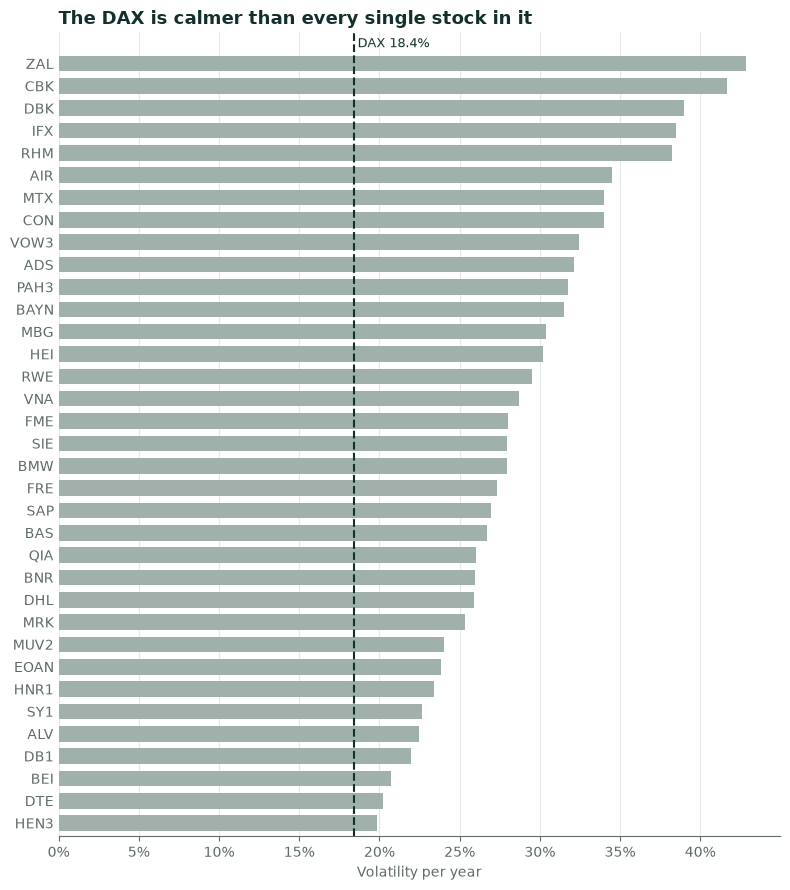

In [188]:


labels = stock_vol.rename(lambda t: t.removesuffix(".DE"))   # "SAP.DE" -> "SAP"

ax = labels.plot.barh(figsize=(8, 9), color=COLORS[2], width=0.7)
ax.axvline(dax_vol, color=COLORS[0], linestyle="--", linewidth=1.5)
ax.text(dax_vol, len(stock_vol) - 0.4, f" DAX {dax_vol:.1%}", color=COLORS[0], fontsize=9, va="bottom")
ax.set_ylim(-0.6, len(stock_vol) + 0.4)

ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

ax.set_xlabel("Volatility per year")
ax.set_ylabel("")
ax.set_title("The DAX is calmer than every single stock in it")
plt.tight_layout()
plt.show()

## 4. Hand crafted Portfolio

In [ ]:
pair_ret = returns[["SAP.DE", "ALV.DE"]].mean(axis=1)

pair_ret.head()

Date
2016-01-05   -0.002398
2016-01-06   -0.029253
2016-01-07   -0.038041
2016-01-08   -0.017574
2016-01-11   -0.002238
dtype: float64

In [ ]:
vol_sap = annual_vol(returns["SAP.DE"])
vol_allianz = annual_vol(returns["ALV.DE"])
mean_both = (vol_sap + vol_allianz)/2
vol_pair_ret = annual_vol(pair_ret)

print(f"Volatilität SAP: {vol_sap:.1%}")
print(f"Volatilität Allianz: {vol_allianz:.1%}")
print(f"Durchschnitt beider Zahlen: {mean_both:.1%}")
print(f"Volatilität Portfolio[SAP, Allianz]: {vol_pair_ret:.1%}")


Volatilität BMW: 27.9%
Volatilität MBG.DE: 30.4%
Durchschnitt beider Zahlen: 29.2%
Volatilität Portfolio[SAP, Allianz]: 27.9%


In [192]:
corr_pair = returns["SAP.DE"].corr(returns["ALV.DE"])

print(f"Korrelation zwischen SAP und Allianz: {corr_pair}")

Korrelation zwischen SAP und Allianz: 0.44225413125043256


## Alle Aktien gleich gewichten

In [196]:
mean_over_days = returns.mean(axis=1)
vola_all_stocks = annual_vol(mean_over_days)
print(f"Volatitlitä über alle Aktien: {vola_all_stocks:.1%}")
print(f"DAX Volatilität: {dax_vol:.1%}")


Volatitlitä über alle Aktien: 17.9%
DAX Volatilität: 18.4%


## Let the Fun begin

In [ ]:
rng = np.random.default_rng(SEED) 
def random_portfolio(tickers, n, rng): 
    return rng.choice(tickers, size=n, replace=False).tolist()

def portfolio_returns(returns, members): 
    return  returns[members].mean(axis=1)

print(random_portfolio(returns.columns, 5, rng))
print(portfolio_returns(returns, ["SAP.DE", "ALV.DE"]))

['MUV2.DE', 'EOAN.DE', 'MBG.DE', 'ALV.DE', 'FME.DE']
['VNA.DE', 'ALV.DE', 'FRE.DE', 'QIA.DE', 'PAH3.DE']
['FRE.DE', 'QIA.DE', 'EOAN.DE', 'DHL.DE', 'BMW.DE']
['HEI.DE', 'BNR.DE', 'FME.DE', 'EOAN.DE', 'PAH3.DE']
['BEI.DE', 'QIA.DE', 'SY1.DE', 'CON.DE', 'MBG.DE']
['SAP.DE', 'RHM.DE', 'EOAN.DE', 'SIE.DE', 'MTX.DE']
['AIR.DE', 'FME.DE', 'HEN3.DE', 'QIA.DE', 'BEI.DE']
Date
2016-01-05    0.007624
2016-01-06    0.005937
2016-01-07   -0.015278
2016-01-08   -0.008374
2016-01-11    0.005847
                ...   
2026-09-24    0.001269
2026-09-25    0.009852
2026-09-28   -0.002748
2026-09-29    0.000359
2026-09-30   -0.006770
Length: 2731, dtype: float64


In [ ]:
tickers = list(returns.columns)

random_generator = np.random.default_rng(SEED)